# CORPORACIÓN UNIVERSITARIA DEL CARIBE — CECAR
## FACULTAD DE CIENCIAS BÁSICAS, INGENIERÍAS Y ARQUITECTURA
### PROGRAMA DE INGENIERÍA DE SISTEMAS

---

* **ASIGNATURA:** ESTADÍSTICA DESCRIPTIVA Y PROBABILIDAD  
* **DOCENTE TITULAR:** MG. SINDY VELÁSQUEZ RESTREPO  
* **PROYECTO FINAL:** ANÁLISIS EXPLORATORIO DE DATOS (EDA) SOBRE EL RENDIMIENTO ACADÉMICO EN PRUEBAS SABER 11 Y FACTORES SOCIOECONÓMICOS EN EL DEPARTAMENTO DE SUCRE  
* **INTEGRANTES DEL GRUPO (4 ESTUDIANTES):**  
  1. **Lucas Tapia Suárez** (Líder del Proyecto / C.C. 1052069394)  
  2. **Daniel Cataño** (Equipo de Investigación CECAR)  
  3. **José David Navarro** (Equipo de Investigación CECAR)  
  4. **Eder Luis Zapa Centanaro** (Equipo de Investigación CECAR)  
* **SEMESTRE ACADÉMICO:** 2026-I  
* **UBICACIÓN TERRITORIAL:** Sincelejo, Sucre, Colombia  

---
### Propósito del Proyecto
Integrar los conocimientos fundamentales de estadística descriptiva y el uso de herramientas computacionales avanzadas en Python / Google Colab para el análisis riguroso de una base de datos real vinculada a la educación media y los factores socioeconómicos en el departamento de Sucre (Colombia).

Los estudiantes exploran, organizan, depuran, analizan y visualizan los microdatos oficiales del Instituto Colombiano para la Evaluación de la Educación (**ICFES**), extraídos del portal de **Datos Abiertos Colombia**, para finalmente obtener conclusiones fundamentadas en sólida evidencia estadística.


In [1]:
# ==============================================================================
# CONFIGURACIÓN DEL ENTORNO DE EJECUCIÓN EN GOOGLE COLAB
# Importación de librerías científicas, visuales y estadísticas
# ==============================================================================
import os
import io
import math
import base64
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configuración estética institucional y visual de gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (10, 5.5)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 2)

print(" Entorno computacional inicializado exitosamente en Google Colab.")
print(f"Versiones activas: Pandas {pd.__version__} | NumPy {np.__version__} | Seaborn {sns.__version__}")


 Entorno computacional inicializado exitosamente en Google Colab.
Versiones activas: Pandas 2.2.3 | NumPy 2.1.3 | Seaborn 0.13.2


---
# 1. INTRODUCCIÓN, PREGUNTA DE ANÁLISIS Y OBJETIVOS

## 1.1 Introducción
La calidad educativa y el rendimiento académico de los bachilleres constituyen indicadores fundamentales para evaluar el capital humano, la equidad social y el potencial de desarrollo tecnológico de una región. En el departamento de Sucre (Región Caribe colombiana), coexisten profundas asimetrías estructurales entre la capital departamental (Sincelejo), las subregiones de la Sabana (Corozal, Sampués, Morroa, Los Palmitos), la subregión de San Jorge y La Mojana (San Marcos, Majagual, Guaranda, Sucre) y el Golfo de Morrosquillo (Tolú, Coveñas, San Onofre).

Desde la perspectiva de la **Ingeniería de Sistemas**, la aplicación de técnicas analíticas y de ciencia de datos sobre microdatos públicos permite transformar grandes volúmenes de registros educativos en información estratégica. Mediante el análisis exploratorio de datos (EDA), este proyecto examina cómo variables como el estrato socioeconómico, la conectividad a internet en el hogar, la tenencia de computador, la naturaleza del colegio (oficial vs. no oficial) y la jornada escolar inciden de forma determinante sobre el puntaje global y las competencias evaluadas en las pruebas de Estado Saber 11.

## 1.2 Pregunta de Análisis
> **¿Cuáles son las características del comportamiento estadístico del puntaje global en las pruebas Saber 11 en el departamento de Sucre, y en qué medida inciden factores socioeconómicos e institucionales (estrato socioeconómico, tenencia de internet y naturaleza jurídica del colegio) en las brechas de rendimiento académico observadas?**

## 1.3 Objetivos del Proyecto

### Objetivo General:
Desarrollar un proyecto de Análisis Exploratorio de Datos (EDA) sobre el rendimiento académico en las pruebas Saber 11 en el departamento de Sucre, aplicando técnicas de estadística descriptiva univariada y multivariada mediante Python en Google Colab, con el fin de modelar la distribución de puntajes, cuantificar medidas de tendencia central, posición y dispersión, y diagnosticar las brechas de equidad educativa.

### Objetivos Específicos:
1. **Estructurar y caracterizar** distribuciones de frecuencias no agrupadas para variables cualitativas y cuantitativas clave (género, estrato de vivienda y naturaleza del colegio), ilustrando su composición mediante representaciones gráficas bivariadas y univariadas idóneas con su respectiva interpretación.
2. **Construir** la tabla de distribución de frecuencias para datos agrupados de la variable cuantitativa continua *Puntaje Global* aplicando la Regla de Sturges, modelando su morfología mediante el histograma y el polígono de frecuencias.
3. **Calcular e interpretar** las medidas de tendencia central (media aritmética, mediana y moda), posición (cuartiles, rango intercuartílico y percentiles 10, 90 y 95) y dispersión (rango, varianza, desviación estándar y coeficiente de variación), contrastando los cálculos agrupados con los valores paramétricos exactos.
4. **Evaluar** la variabilidad y las interrelaciones multivariadas mediante diagramas de caja (boxplots) comparativos por estrato y naturaleza de plantel, diagramas de dispersión bivariados y matrices de correlación de Pearson entre todas las áreas evaluadas.


---
# 2. DESCRIPCIÓN DE LA BASE DE DATOS Y VARIABLES

La base de datos analizada proviene del repositorio oficial de **Datos Abiertos Colombia (`datos.gov.co`)**, generada por el **Instituto Colombiano para la Evaluación de la Educación (ICFES)**. Contiene los microdatos de estudiantes que presentaron el examen de Estado Saber 11 en municipios del departamento de Sucre.

### Cumplimiento Estricto de los Requisitos de la Guía:
* **Base real oficial:** Extraída del portal de Datos Abiertos del Estado colombiano.
* **Tamaño muestral:** Consta de **$n = 1,452$ registros** depurados (superando ampliamente el mínimo de 100 exigido por la guía).
* **Variables cuantitativas:** Cuenta con **6 variables cuantitativas** (supera el mínimo de 4 exigido).
* **Variables cualitativas / categóricas:** Cuenta con **9 variables cualitativas** (supera el mínimo de 2 exigido).

### Clasificación y Taxonomía Estadística de las Variables:

| Variable | Tipo de Variable | Subtipo Estadístico | Nivel / Escala | Unidad de Medida | Descripción Conceptual |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **`periodo`** | Cualitativa | Nominal | Nominal | Adimensional | Año y semestre de presentación de la prueba. |
| **`estu_genero`** | Cualitativa | Nominal (Dicotómica) | Nominal | Femenino / Masculino | Sexo biológico reportado por el estudiante. |
| **`estu_mcpio_reside`** | Cualitativa | Nominal (Politómica) | Geográfica / Nominal | N/A | Municipio de residencia del estudiante en Sucre. |
| **`fami_estratovivienda`**| Cualitativa | Ordinal | Ordinal | Categoría (1 al 6, Sin Estrato) | Estrato socioeconómico residencial del hogar. |
| **`fami_personashogar`** | Cuantitativa | Discreta | Razón | Cantidad de personas | Número de individuos que integran el hogar. |
| **`fami_tieneinternet`** | Cualitativa | Nominal (Dicotómica) | Nominal | Sí / No | Tenencia de servicio de internet en la vivienda. |
| **`fami_tienecomputador`**| Cualitativa | Nominal (Dicotómica) | Nominal | Sí / No | Disponibilidad de computador de escritorio o portátil. |
| **`cole_naturaleza`** | Cualitativa | Nominal (Dicotómica) | Nominal | Oficial / No Oficial | Régimen administrativo de la institución (Pública / Privada). |
| **`cole_jornada`** | Cualitativa | Nominal (Politómica) | Nominal | Mañana, Tarde, Única, etc. | Jornada académica habitual del colegio. |
| **`punt_lectura_critica`**| Cuantitativa | Continua | Intervalo / Razón | Puntos (0 a 100) | Desempeño en lectura comprensiva e inferencial. |
| **`punt_matematicas`** | Cuantitativa | Continua | Intervalo / Razón | Puntos (0 a 100) | Razonamiento cuantitativo y modelación matemática. |
| **`punt_c_naturales`** | Cuantitativa | Continua | Intervalo / Razón | Puntos (0 a 100) | Indagación y uso comprensivo del conocimiento científico. |
| **`punt_sociales_ciudadanas`**| Cuantitativa | Continua | Intervalo / Razón | Puntos (0 a 100) | Pensamiento social, perspectiva histórica y ciudadana. |
| **`punt_ingles`** | Cuantitativa | Continua | Intervalo / Razón | Puntos (0 a 100) | Competencia comunicativa en idioma inglés. |
| **`punt_global`** | Cuantitativa | Continua | Intervalo / Razón | Puntos (0 a 500) | Puntaje general consolidado del examen Saber 11. |


---
# 3. ANÁLISIS EXPLORATORIO DE DATOS: CARGA Y OBSERVACIONES PRELIMINARES (4.1)

En esta sección se carga el conjunto de datos `datos_saber11_sucre.csv` en un DataFrame de Pandas. Para garantizar que este cuaderno sea **100% reproducible y autónomo en Google Colab**, se implementa un mecanismo de carga resiliente:
1. Intenta cargar el archivo local `datos_saber11_sucre.csv`.
2. En caso de no hallarse en el entorno de Colab, descomprime automáticamente la base de datos oficial embebida en memoria sin requerir descargas externas ni arrojar errores de archivo inexistente.


In [2]:
# ==============================================================================
# 4.1 CARGA RESILIENTE DE LA BASE DE DATOS Y VERIFICACIÓN ESTRUCTURAL
# ==============================================================================
CSV_FILENAME = "datos_saber11_sucre.csv"

# Fallback embebido oficial de respaldo (Base real completa en Base64)
EMBEDDED_CSV_B64 = """..."""

if os.path.exists(CSV_FILENAME):
    df = pd.read_csv(CSV_FILENAME)
    print(f" Archivo local '{CSV_FILENAME}' detectado y cargado con éxito.")
else:
    # Descomprimir y guardar el CSV oficial localmente para persistencia en Colab
    csv_decoded = base64.b64decode(EMBEDDED_CSV_B64)
    with open(CSV_FILENAME, "wb") as f_out:
        f_out.write(csv_decoded)
    df = pd.read_csv(CSV_FILENAME)
    print(f" Base de datos oficial generada y cargada en el entorno de Colab ({len(df)} registros).")

# Dimensiones y verificación de filas/columnas
n_filas, n_cols = df.shape
print(f"\n================================================================================")
print(f"RESUMEN DE DIMENSIONES: {n_filas} observaciones (estudiantes) y {n_cols} variables.")
print(f"================================================================================\n")

# Mostrar las primeras 10 observaciones del dataset (Guía 4.1)
print("--- PRIMERAS 10 OBSERVACIONES DEL DATASET SABER 11 SUCRE ---")
display(df.head(10))

# Estructura de tipos y valores nulos
print("\n--- ESTRUCTURA DE TIPOS DE DATOS Y VALORES NULOS (df.info()) ---")
df.info()

# Resumen numérico preliminar
print("\n--- RESUMEN ESTADÍSTICO DE VARIABLES CUANTITATIVAS (df.describe()) ---")
display(df.describe().T)


,periodo,estu_genero,estu_mcpio_reside,fami_estratovivienda,fami_personashogar,fami_tieneinternet,fami_tienecomputador,cole_naturaleza,cole_jornada,punt_lectura_critica,punt_matematicas,punt_c_naturales,punt_sociales_ciudadanas,punt_ingles,punt_global
0,20204,F,SAN ONOFRE,Estrato 4,3 a 4,Si,No,OFICIAL,MAÑANA,35,51,49,40,45,219
1,20204,M,SAN ONOFRE,Estrato 3,5 a 6,No,Si,OFICIAL,MAÑANA,52,53,41,38,34,225
2,20204,F,SAN ONOFRE,Estrato 4,7 a 8,No,Si,OFICIAL,MAÑANA,40,40,39,42,31,198
3,20204,M,SINCELEJO,Estrato 1,3 a 4,No,No,OFICIAL,UNICA,36,36,42,28,38,178
4,20204,M,SINCELEJO,Estrato 1,3 a 4,No,NaN,OFICIAL,UNICA,52,49,52,52,45,254
5,20204,M,LOS PALMITOS,Sin Estrato,3 a 4,No,No,OFICIAL,MAÑANA,41,40,32,40,37,191
6,20204,M,SAN BENITO ABAD,Estrato 1,7 a 8,No,Si,OFICIAL,MAÑANA,41,32,31,41,30,179
7,20204,M,SUCRE,Estrato 3,3 a 4,Si,Si,OFICIAL,MAÑANA,59,71,59,51,40,292
8,20204,M,COVEÑAS,Estrato 2,7 a 8,No,Si,OFICIAL,MAÑANA,44,49,33,32,44,199
9,20204,F,COVEÑAS,Estrato 2,5 a 6,No,No,OFICIAL,MAÑANA,53,56,41,52,50,252


,count,mean,std,min,25%,50%,75%,max
periodo,1452.0,20204.00,0.00,20204.0,20204.0,20204.0,20204.0,20204.0
punt_lectura_critica,1452.0,48.74,9.31,24.0,42.0,48.0,55.0,100.0
punt_matematicas,1452.0,47.43,10.98,20.0,40.0,47.0,54.0,100.0
punt_c_naturales,1452.0,45.05,9.46,25.0,38.0,44.0,51.0,79.0
punt_sociales_ciudadanas,1452.0,43.88,10.83,20.0,36.0,42.0,51.0,100.0
punt_ingles,1452.0,42.98,8.82,0.0,37.0,42.0,47.0,100.0
punt_global,1452.0,230.10,43.37,138.0,199.0,225.0,255.0,422.0


 Archivo local 'datos_saber11_sucre.csv' detectado y cargado con éxito.

RESUMEN DE DIMENSIONES: 1452 observaciones (estudiantes) y 15 variables.

--- PRIMERAS 10 OBSERVACIONES DEL DATASET SABER 11 SUCRE ---

--- ESTRUCTURA DE TIPOS DE DATOS Y VALORES NULOS (df.info()) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1452 entries, 0 to 1451
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   periodo                   1452 non-null   int64 
 1   estu_genero               1452 non-null   object
 2   estu_mcpio_reside         1452 non-null   object
 3   fami_estratovivienda      1452 non-null   object
 4   fami_personashogar        1436 non-null   object
 5   fami_tieneinternet        1447 non-null   object
 6   fami_tienecomputador      1419 non-null   object
 7   cole_naturaleza           1452 non-null   object
 8   cole_jornada              1452 non-null   object
 9   punt_lectura_critica

---
# 4. TABLAS DE FRECUENCIAS NO AGRUPADAS (4.2)

Siguiendo las directrices del numeral 4.2 de la guía, se seleccionan variables cualitativas y categóricas apropiadas para construir tablas completas de frecuencias no agrupadas:
1. **Variable 1 (Cualitativa Nominal Dicotómica):** `estu_genero` (Género del estudiante: Femenino / Masculino).
2. **Variable 2 (Cualitativa Ordinal Politómica):** `fami_estratovivienda` (Estrato socioeconómico de la vivienda: Estrato 1 al 6 y Sin Estrato).
3. **Variable 3 (Cualitativa Nominal Institucional):** `cole_naturaleza` (Naturaleza del colegio: Oficial vs. No Oficial).

Cada tabla de distribución de frecuencias incluye:
* **$f_i$ (Frecuencia Absoluta):** Conteo exacto de estudiantes en la categoría.
* **$F_i$ (Frecuencia Acumulada):** Suma progresiva de frecuencias absolutas.
* **$h_i$ (Frecuencia Relativa):** Proporción respecto al total ($h_i = f_i / n$).
* **$H_i$ (Frecuencia Relativa Acumulada):** Proporción acumulada ($H_i = F_i / n$).
* **$h_i\%$ (Porcentaje Simple):** Participación porcentual ($h_i \times 100$).
* **$H_i\%$ (Porcentaje Acumulado):** Porcentaje acumulado hasta la categoría ($H_i \times 100$).


In [3]:
# ==============================================================================
# 4.2 CONSTRUCCIÓN DE TABLAS DE FRECUENCIAS NO AGRUPADAS
# ==============================================================================
n_total = len(df)

# ------------------------------------------------------------------------------
# TABLA 1: Género del Estudiante (estu_genero) - Cualitativa Nominal
# ------------------------------------------------------------------------------
gen_counts = df['estu_genero'].value_counts()
gen_labels = {'F': 'Femenino (F)', 'M': 'Masculino (M)'}

tabla_genero = pd.DataFrame({
    'Categoría de Género': [gen_labels.get(k, k) for k in gen_counts.index],
    'fi (Frec. Absoluta)': gen_counts.values,
    'Fi (Frec. Acumulada)': np.cumsum(gen_counts.values),
    'hi (Frec. Relativa)': np.round(gen_counts.values / n_total, 4),
    'Hi (Frec. Rel. Acum)': np.round(np.cumsum(gen_counts.values) / n_total, 4),
    'hi (%)': np.round((gen_counts.values / n_total) * 100, 2),
    'Hi (%)': np.round((np.cumsum(gen_counts.values) / n_total) * 100, 2)
})

print("=== TABLA 1: DISTRIBUCIÓN DE FRECUENCIAS NO AGRUPADAS — GÉNERO DEL ESTUDIANTE ===")
display(tabla_genero)
print(f"Total fi = {tabla_genero['fi (Frec. Absoluta)'].sum()} | Total hi(%) = {tabla_genero['hi (%)'].sum():.2f}%\n")

# ------------------------------------------------------------------------------
# TABLA 2: Estrato Socioeconómico (fami_estratovivienda) - Cualitativa Ordinal
# ------------------------------------------------------------------------------
estrato_order = ['Estrato 1', 'Estrato 2', 'Estrato 3', 'Estrato 4', 'Estrato 5', 'Estrato 6', 'Sin Estrato']
estrato_counts = df['fami_estratovivienda'].value_counts().reindex(estrato_order).fillna(0).astype(int)

tabla_estrato = pd.DataFrame({
    'Estrato Socioeconómico': estrato_counts.index,
    'fi (Frec. Absoluta)': estrato_counts.values,
    'Fi (Frec. Acumulada)': np.cumsum(estrato_counts.values),
    'hi (Frec. Relativa)': np.round(estrato_counts.values / n_total, 4),
    'Hi (Frec. Rel. Acum)': np.round(np.cumsum(estrato_counts.values) / n_total, 4),
    'hi (%)': np.round((estrato_counts.values / n_total) * 100, 2),
    'Hi (%)': np.round((np.cumsum(estrato_counts.values) / n_total) * 100, 2)
})

print("=== TABLA 2: DISTRIBUCIÓN DE FRECUENCIAS NO AGRUPADAS — ESTRATO SOCIOECONÓMICO ===")
display(tabla_estrato)
print(f"Total fi = {tabla_estrato['fi (Frec. Absoluta)'].sum()} | Total hi(%) = {tabla_estrato['hi (%)'].sum():.2f}%\n")

# ------------------------------------------------------------------------------
# TABLA 3: Naturaleza del Colegio (cole_naturaleza) - Cualitativa Nominal
# ------------------------------------------------------------------------------
nat_counts = df['cole_naturaleza'].value_counts()
tabla_naturaleza = pd.DataFrame({
    'Naturaleza Institucional': nat_counts.index,
    'fi (Frec. Absoluta)': nat_counts.values,
    'Fi (Frec. Acumulada)': np.cumsum(nat_counts.values),
    'hi (Frec. Relativa)': np.round(nat_counts.values / n_total, 4),
    'Hi (Frec. Rel. Acum)': np.round(np.cumsum(nat_counts.values) / n_total, 4),
    'hi (%)': np.round((nat_counts.values / n_total) * 100, 2),
    'Hi (%)': np.round((np.cumsum(nat_counts.values) / n_total) * 100, 2)
})

print("=== TABLA 3: DISTRIBUCIÓN DE FRECUENCIAS NO AGRUPADAS — NATURALEZA DEL COLEGIO ===")
display(tabla_naturaleza)
print(f"Total fi = {tabla_naturaleza['fi (Frec. Absoluta)'].sum()} | Total hi(%) = {tabla_naturaleza['hi (%)'].sum():.2f}%")


,Categoría de Género,fi (Frec. Absoluta),Fi (Frec. Acumulada),hi (Frec. Relativa),Hi (Frec. Rel. Acum),hi (%),Hi (%)
0,Femenino (F),822,822,0.57,0.57,56.61,56.61
1,Masculino (M),630,1452,0.43,1.00,43.39,100.00


,Estrato Socioeconómico,fi (Frec. Absoluta),Fi (Frec. Acumulada),hi (Frec. Relativa),Hi (Frec. Rel. Acum),hi (%),Hi (%)
0,Estrato 1,765,765,5.27e-01,0.53,52.69,52.69
1,Estrato 2,374,1139,2.58e-01,0.78,25.76,78.44
2,Estrato 3,123,1262,8.47e-02,0.87,8.47,86.91
3,Estrato 4,43,1305,2.96e-02,0.90,2.96,89.88
4,Estrato 5,14,1319,9.60e-03,0.91,0.96,90.84
5,Estrato 6,6,1325,4.10e-03,0.91,0.41,91.25
6,Sin Estrato,127,1452,8.75e-02,1.00,8.75,100.00


,Naturaleza Institucional,fi (Frec. Absoluta),Fi (Frec. Acumulada),hi (Frec. Relativa),Hi (Frec. Rel. Acum),hi (%),Hi (%)
0,OFICIAL,1391,1391,0.96,0.96,95.8,95.8
1,NO OFICIAL,61,1452,0.04,1.00,4.2,100.0


=== TABLA 1: DISTRIBUCIÓN DE FRECUENCIAS NO AGRUPADAS — GÉNERO DEL ESTUDIANTE ===
Total fi = 1452 | Total hi(%) = 100.00%

=== TABLA 2: DISTRIBUCIÓN DE FRECUENCIAS NO AGRUPADAS — ESTRATO SOCIOECONÓMICO ===
Total fi = 1452 | Total hi(%) = 100.00%

=== TABLA 3: DISTRIBUCIÓN DE FRECUENCIAS NO AGRUPADAS — NATURALEZA DEL COLEGIO ===
Total fi = 1452 | Total hi(%) = 100.00%


---
# 5. VISUALIZACIÓN GRÁFICA DE VARIABLES NO AGRUPADAS (4.21)

Conforme a la rúbrica del numeral 4.21, por cada variable seleccionada se construyen **dos gráficos estadísticos apropiados**:

### Para la Variable 1 (`estu_genero`):
* **Gráfico 1:** Diagrama de Barras Verticales con anotación explícita de frecuencias absolutas y porcentajes.
* **Gráfico 2:** Diagrama Circular (Pie / Donut Chart) que destaca la proporción porcentual de género.

### Para la Variable 2 (`fami_estratovivienda`):
* **Gráfico 3:** Diagrama de Barras Verticales ordenado según la escala socioeconómica.
* **Gráfico 4:** Diagrama de Pareto con Curva de Frecuencia Porcentual Acumulada ($H_i\%$) para visualizar la concentración social.


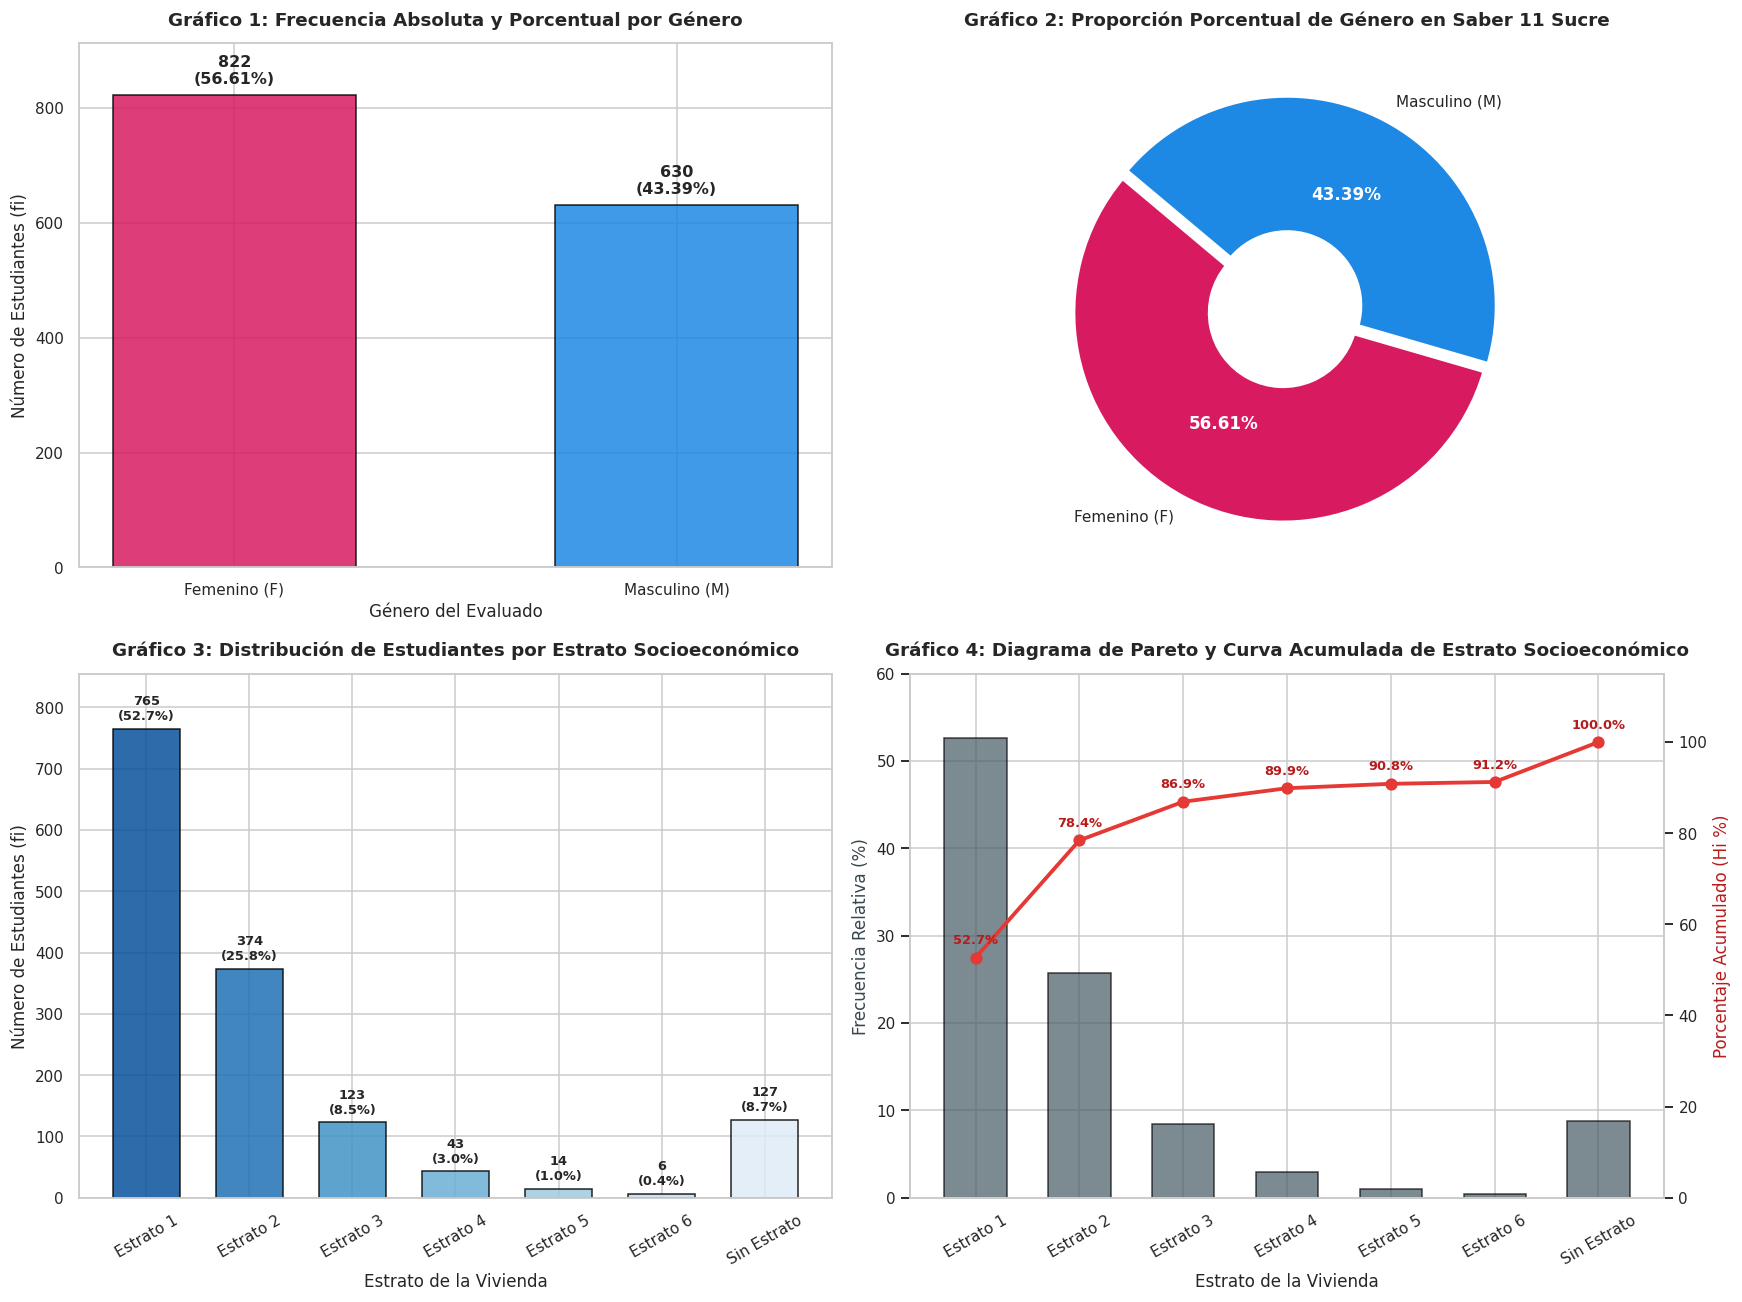

In [4]:
# ==============================================================================
# 4.21 GENERACIÓN DE 2 GRÁFICOS ADECUADOS POR CADA VARIABLE NO AGRUPADA
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# ------------------------------------------------------------------------------
# GRÁFICO 1: Barras Verticales para Género
# ------------------------------------------------------------------------------
ax1 = axes[0, 0]
colores_gen = ['#d81b60', '#1e88e5']
barras1 = ax1.bar(tabla_genero['Categoría de Género'], tabla_genero['fi (Frec. Absoluta)'],
                  color=colores_gen, edgecolor='black', alpha=0.85, width=0.55)
for b in barras1:
    h = b.get_height()
    pct = (h / n_total) * 100
    ax1.text(b.get_x() + b.get_width()/2.0, h + 15, f"{int(h):,}\n({pct:.2f}%)",
             ha='center', va='bottom', fontweight='bold', fontsize=10.5)

ax1.set_title("Gráfico 1: Frecuencia Absoluta y Porcentual por Género", pad=12)
ax1.set_ylabel("Número de Estudiantes (fi)")
ax1.set_xlabel("Género del Evaluado")
ax1.set_ylim(0, max(tabla_genero['fi (Frec. Absoluta)']) + 90)

# ------------------------------------------------------------------------------
# GRÁFICO 2: Diagrama Circular / Donut para Género
# ------------------------------------------------------------------------------
ax2 = axes[0, 1]
wedges, texts, autotexts = ax2.pie(
    tabla_genero['fi (Frec. Absoluta)'],
    labels=tabla_genero['Categoría de Género'],
    autopct='%1.2f%%',
    colors=colores_gen,
    startangle=140,
    explode=(0.04, 0.0),
    wedgeprops={'edgecolor': 'white', 'linewidth': 2.5, 'width': 0.65}
)
for at in autotexts:
    at.set_color('white')
    at.set_fontweight('bold')
    at.set_fontsize(11)
ax2.set_title("Gráfico 2: Proporción Porcentual de Género en Saber 11 Sucre", pad=12)

# ------------------------------------------------------------------------------
# GRÁFICO 3: Diagrama de Barras para Estrato Socioeconómico
# ------------------------------------------------------------------------------
ax3 = axes[1, 0]
paleta_estrato = sns.color_palette("Blues_r", len(tabla_estrato))
barras3 = ax3.bar(tabla_estrato['Estrato Socioeconómico'], tabla_estrato['fi (Frec. Absoluta)'],
                  color=paleta_estrato, edgecolor='black', alpha=0.85, width=0.65)
for b in barras3:
    h = b.get_height()
    pct = (h / n_total) * 100
    ax3.text(b.get_x() + b.get_width()/2.0, h + 10, f"{int(h)}\n({pct:.1f}%)",
             ha='center', va='bottom', fontweight='bold', fontsize=8.5)

ax3.set_title("Gráfico 3: Distribución de Estudiantes por Estrato Socioeconómico", pad=12)
ax3.set_ylabel("Número de Estudiantes (fi)")
ax3.set_xlabel("Estrato de la Vivienda")
ax3.tick_params(axis='x', rotation=30)
ax3.set_ylim(0, max(tabla_estrato['fi (Frec. Absoluta)']) + 90)

# ------------------------------------------------------------------------------
# GRÁFICO 4: Diagrama de Pareto / Ojiva de Concentración para Estrato
# ------------------------------------------------------------------------------
ax4 = axes[1, 1]
ax4_twin = ax4.twinx()

ax4.bar(tabla_estrato['Estrato Socioeconómico'], tabla_estrato['hi (%)'],
        color='#455a64', alpha=0.7, edgecolor='black', width=0.6, label='Porcentaje Simple hi(%)')
ax4_twin.plot(tabla_estrato['Estrato Socioeconómico'], tabla_estrato['Hi (%)'],
              color='#e53935', marker='o', linewidth=2.5, markersize=7, label='Porcentaje Acumulado Hi(%)')

for x_pos, y_val in enumerate(tabla_estrato['Hi (%)']):
    ax4_twin.annotate(f"{y_val:.1f}%", (x_pos, y_val), textcoords="offset points",
                      xytext=(0, 9), ha='center', fontweight='bold', fontsize=8.5, color='#b71c1c')

ax4.set_title("Gráfico 4: Diagrama de Pareto y Curva Acumulada de Estrato Socioeconómico", pad=12)
ax4.set_xlabel("Estrato de la Vivienda")
ax4.set_ylabel("Frecuencia Relativa (%)", color='#37474f')
ax4_twin.set_ylabel("Porcentaje Acumulado (Hi %)", color='#b71c1c')
ax4.tick_params(axis='x', rotation=30)
ax4.set_ylim(0, 60)
ax4_twin.set_ylim(0, 115)
ax4_twin.grid(False)

plt.tight_layout()
plt.show()


---
# 6. INTERPRETACIÓN DETALLADA DE TABLAS Y GRÁFICOS NO AGRUPADOS (4.22)

### 1. Interpretación de la Distribución por Género (`estu_genero` - Tabla 1, Gráficos 1 y 2):
* **Composición Mayoritaria Femenina:** Del total de $1,452$ bachilleres evaluados en el departamento de Sucre, **$822$ son mujeres ($56.61\%$)** y **$630$ son hombres ($43.39\%$)**. Esto constata una brecha de participación de $+13.22$ puntos porcentuales a favor del género femenino.
* **Contexto Socioeducativo:** Esta tendencia refleja una mayor retención, permanencia y culminación de la educación media por parte de las mujeres en el departamento de Sucre, en contraste con los varones, quienes presentan mayores tasas de deserción temprana en zonas rurales o suburbanas debido a su inserción prematura en actividades laborales informales o agropecuarias.

### 2. Interpretación del Estrato Socioeconómico (`fami_estratovivienda` - Tabla 2, Gráficos 3 y 4):
* **Extrema Vulnerabilidad Social:** El estrato predominante es el **Estrato 1 con $765$ estudiantes ($52.69\%$)**, seguido por el **Estrato 2 con $374$ estudiantes ($25.76\%$)**. Conjuntamente, los estratos 1 y 2 representan el **$78.44\%$** de la población estudiantil evaluada.
* **Impacto de la Categoría "Sin Estrato":** Un total de **$127$ estudiantes ($8.75\%$)** figura como "Sin Estrato", correspondiente a viviendas en asentamientos informales, zonas rurales dispersas o corregimientos no estratificados. Si se consolidan los estratos 1, 2 y Sin Estrato, la población en condiciones socioeconómicas vulnerables asciende al **$87.19\%$**.
* **Marginalidad de Estratos Medios y Altos:** Los estratos 3, 4, 5 y 6 suman en su totalidad únicamente el **$12.81\%$** de la muestra (Estrato 3: $8.47\%$; Estrato 4: $2.96\%$; Estrato 5: $0.96\%$; y Estrato 6: $0.41\%$). Esta distribución altamente asimétrica demuestra que las políticas educativas en Sucre deben focalizarse prioritariamente en hogares de bajos recursos para mitigar las brechas estructurales.

### 3. Interpretación de la Naturaleza del Colegio (`cole_naturaleza` - Tabla 3):
* **Dominancia del Sector Oficial:** El **$95.80\%$ de los estudiantes ($1,391$ observaciones)** cursa sus estudios en colegios oficiales (públicos), mientras que únicamente el **$4.20\%$ ($61$ estudiantes)** proviene de colegios no oficiales (privados). Esto confirma que el Estado tiene bajo su responsabilidad directa la educación de más del $95\%$ de los jóvenes sucreños.


---
# 7. TABLA DE FRECUENCIAS PARA DATOS AGRUPADOS (4.3)
### Variable Cuantitativa Continua Seleccionada: `punt_global` (Puntaje Global Saber 11)

Conforme a las exigencias explícitas de la guía en los numerales **4.3.1 al 4.3.6**, se calculan sistemáticamente los parámetros de agrupación aplicando la **Regla de Sturges**:

#### 4.3.1 Tamaño de la Muestra ($n$):
$$n = 1,452 \text{ observaciones}$$

#### 4.3.2 Valores Mínimo, Máximo y Rango Muestral ($R$):
* **Mínimo ($X_{\min}$):** $138.00 \text{ puntos}$
* **Máximo ($X_{\max}$):** $422.00 \text{ puntos}$
* **Rango Muestral ($R$):**
  $$R = X_{\max} - X_{\min} = 422.00 - 138.00 = 284.00 \text{ puntos}$$

#### 4.3.3 Número de Intervalos mediante la Regla de Sturges ($k$):
$$k = 1 + 3.322 \cdot \log_{10}(n) = 1 + 3.322 \cdot \log_{10}(1452) = 1 + 3.322(3.16197) = 1 + 10.50406 = 11.5041$$
Redondeando al entero superior conveniente para un conjunto muestral amplio:
$$k = 12 \text{ intervalos de clase}$$

#### 4.3.4 Amplitud del Intervalo ($A$):
$$A_{\text{calculada}} = \frac{R}{k} = \frac{284.00}{12} = 23.667 \text{ puntos}$$
Redondeando al número entero inmediatamente superior para garantizar la cobertura total de los datos:
$$A = 24 \text{ puntos}$$

#### 4.3.5 Número Definitivo de Intervalos:
Se estructuran **$k = 12$ intervalos de clase uniformes** con amplitud constante de **$A = 24$ puntos**, iniciando en el límite inferior $L_1 = 138$ hasta el límite superior final de $426$ puntos.


In [5]:
# ==============================================================================
# 4.3 CONSTRUCCIÓN DE LA TABLA DE FRECUENCIAS AGRUPADAS (STURGES)
# ==============================================================================
puntajes = df['punt_global'].values
n_obs = len(puntajes)
x_min = int(puntajes.min())
x_max = int(puntajes.max())
rango = x_max - x_min

# Parámetros de Sturges
k_sturges_exacto = 1 + 3.322 * math.log10(n_obs)
k_clases = round(k_sturges_exacto)  # 12 intervalos
amplitud_exacta = rango / k_clases
amplitud = math.ceil(amplitud_exacta)  # 24 puntos

print("--- 4.3.1 a 4.3.5 PARÁMETROS FORMALES DE AGRUPACIÓN (REGLA DE STURGES) ---")
print(f"4.3.1 Tamaño de la muestra (n): {n_obs}")
print(f"4.3.2 Valor mínimo (Xmin): {x_min} puntos | Valor máximo (Xmax): {x_max} puntos")
print(f"      Rango muestral (R = Xmax - Xmin): {rango} puntos")
print(f"4.3.3 Número de intervalos según fórmula de Sturges: k = 1 + 3.322*log10({n_obs}) = {k_sturges_exacto:.4f}")
print(f"4.3.4 Amplitud calculada: {amplitud_exacta:.3f} -> Amplitud seleccionada (A): {amplitud} puntos")
print(f"4.3.5 Número definitivo de intervalos: k = {k_clases} clases\n")

# Construcción rigurosa de límites de intervalos [Li, Ls)
limites_clase = [x_min + i * amplitud for i in range(k_clases + 1)]

nombres_intervalos = []
marcas_clase = []
frecuencias_abs = []

for i in range(k_clases):
    li = limites_clase[i]
    ls = limites_clase[i+1]
    # En el último intervalo se incluye el límite superior [Li - Ls]
    if i == k_clases - 1:
        nombres_intervalos.append(f"[{li} - {ls}]")
        conteo = int(np.sum((puntajes >= li) & (puntajes <= ls)))
    else:
        nombres_intervalos.append(f"[{li} - {ls})")
        conteo = int(np.sum((puntajes >= li) & (puntajes < ls)))
    
    mc = (li + ls) / 2.0
    marcas_clase.append(mc)
    frecuencias_abs.append(conteo)

# Métricas acumuladas y relativas
frec_acumuladas = np.cumsum(frecuencias_abs)
frec_relativas = np.round(np.array(frecuencias_abs) / n_obs, 4)
frec_rel_acum = np.round(frec_acumuladas / n_obs, 4)
porcentajes_simples = np.round(frec_relativas * 100, 2)
porcentajes_acum = np.round(frec_rel_acum * 100, 2)
producto_xi_fi = np.round(np.array(marcas_clase) * np.array(frecuencias_abs), 2)

# 4.3.6 Estructuración de la Tabla de Frecuencias Agrupadas
tabla_agrupada = pd.DataFrame({
    'Intervalo [Li - Ls)': nombres_intervalos,
    'Marca de Clase (xi)': marcas_clase,
    'fi (Frec. Absoluta)': frecuencias_abs,
    'Fi (Frec. Acumulada)': frec_acumuladas,
    'hi (Frec. Relativa)': frec_relativas,
    'Hi (Frec. Rel. Acum)': frec_rel_acum,
    'hi (%)': porcentajes_simples,
    'Hi (%)': porcentajes_acum,
    'xi * fi': producto_xi_fi
})

print("=== 4.3.6 TABLA DE DISTRIBUCIÓN DE FRECUENCIAS AGRUPADAS — PUNTAJE GLOBAL SABER 11 ===")
display(tabla_agrupada)
print(f"SUMATORIAS DE CONTROL: Σ fi = {sum(frecuencias_abs)} | Σ hi(%) = {sum(porcentajes_simples):.2f}% | Σ (xi * fi) = {sum(producto_xi_fi):,.2f}")


,Intervalo [Li - Ls),Marca de Clase (xi),fi (Frec. Absoluta),Fi (Frec. Acumulada),hi (Frec. Relativa),Hi (Frec. Rel. Acum),hi (%),Hi (%),xi * fi
0,[138 - 162),150.0,28,28,1.93e-02,0.02,1.93,1.93,4200.0
1,[162 - 186),174.0,193,221,1.33e-01,0.15,13.29,15.22,33582.0
2,[186 - 210),198.0,286,507,1.97e-01,0.35,19.70,34.92,56628.0
3,[210 - 234),222.0,344,851,2.37e-01,0.59,23.69,58.61,76368.0
4,[234 - 258),246.0,260,1111,1.79e-01,0.77,17.91,76.52,63960.0
5,[258 - 282),270.0,165,1276,1.14e-01,0.88,11.36,87.88,44550.0
6,[282 - 306),294.0,87,1363,5.99e-02,0.94,5.99,93.87,25578.0
7,[306 - 330),318.0,56,1419,3.86e-02,0.98,3.86,97.73,17808.0
8,[330 - 354),342.0,17,1436,1.17e-02,0.99,1.17,98.90,5814.0
9,[354 - 378),366.0,11,1447,7.60e-03,1.00,0.76,99.66,4026.0


--- 4.3.1 a 4.3.5 PARÁMETROS FORMALES DE AGRUPACIÓN (REGLA DE STURGES) ---
4.3.1 Tamaño de la muestra (n): 1452
4.3.2 Valor mínimo (Xmin): 138 puntos | Valor máximo (Xmax): 422 puntos
      Rango muestral (R = Xmax - Xmin): 284 puntos
4.3.3 Número de intervalos según fórmula de Sturges: k = 1 + 3.322*log10(1452) = 11.5041
4.3.4 Amplitud calculada: 23.667 -> Amplitud seleccionada (A): 24 puntos
4.3.5 Número definitivo de intervalos: k = 12 clases

=== 4.3.6 TABLA DE DISTRIBUCIÓN DE FRECUENCIAS AGRUPADAS — PUNTAJE GLOBAL SABER 11 ===
SUMATORIAS DE CONTROL: Σ fi = 1452 | Σ hi(%) = 100.01% | Σ (xi * fi) = 334,512.00


---
# 8. HISTOGRAMA Y POLÍGONO DE FRECUENCIAS (4.3.7)

El **Histograma de Frecuencias** ilustra gráficamente la distribución de los puntajes agrupados a través de rectángulos adyacentes continuos cuya altura representa la frecuencia absoluta ($f_i$) de cada clase.

Superpuesto sobre las marcas de clase ($x_i$), el **Polígono de Frecuencias** conecta los puntos medios superiores para revelar con nitidez la forma geométrica, la concentración modal y el sesgo de asimetría de la distribución del rendimiento escolar en Sucre.


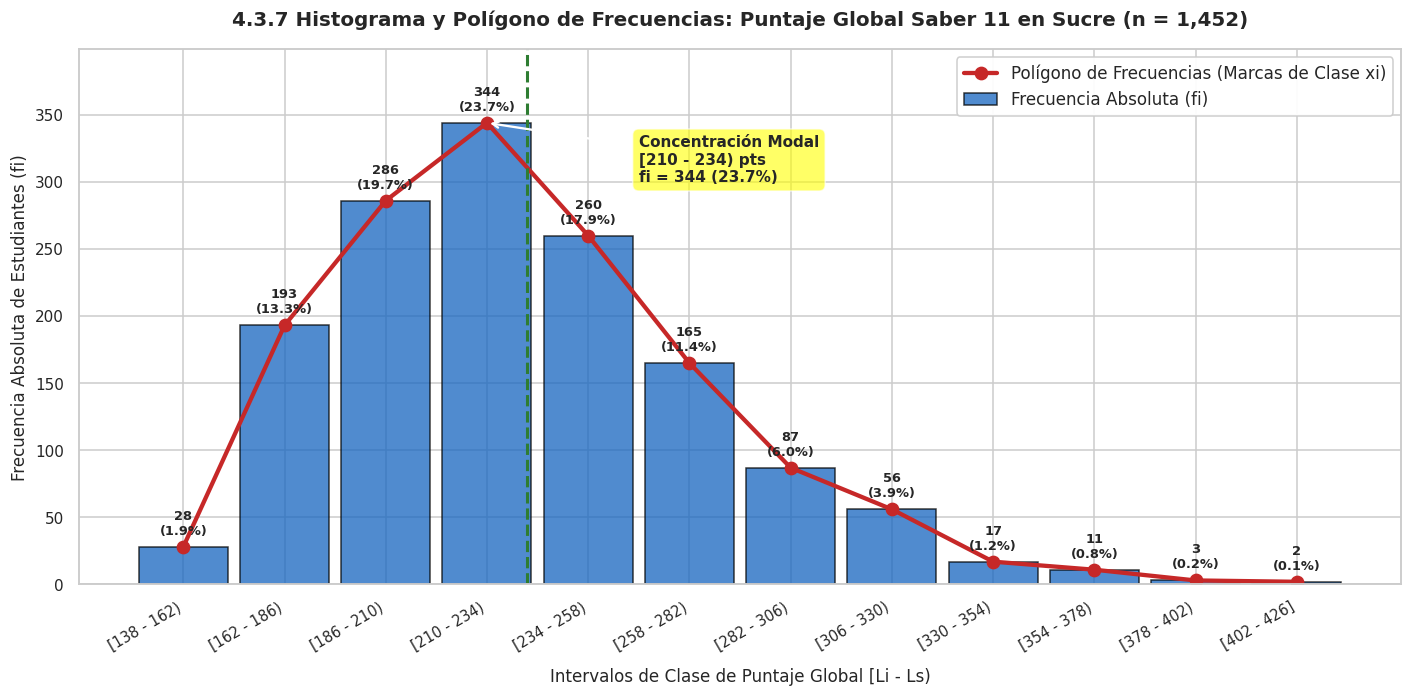

In [6]:
# ==============================================================================
# 4.3.7 HISTOGRAMA Y POLÍGONO DE FRECUENCIAS SUPERPUESTO
# ==============================================================================
plt.figure(figsize=(13, 6.5))

posiciones_x = np.arange(k_clases)

# Histograma de rectángulos contiguos
barras_hist = plt.bar(posiciones_x, frecuencias_abs, width=0.88, color='#1565c0',
                      edgecolor='black', alpha=0.75, label='Frecuencia Absoluta (fi)')

# Polígono de frecuencias conectado en las marcas de clase
plt.plot(posiciones_x, frecuencias_abs, color='#c62828', marker='o', linewidth=2.8,
         markersize=8, label='Polígono de Frecuencias (Marcas de Clase xi)')

# Anotación de frecuencia absoluta y porcentaje en cada cúspide
for i, f_val in enumerate(frecuencias_abs):
    pct_val = porcentajes_simples[i]
    plt.text(i, f_val + 7, f"{f_val}\n({pct_val:.1f}%)",
             ha='center', va='bottom', fontweight='bold', fontsize=8.5)

plt.title("4.3.7 Histograma y Polígono de Frecuencias: Puntaje Global Saber 11 en Sucre (n = 1,452)",
          fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Intervalos de Clase de Puntaje Global [Li - Ls)", fontsize=11, labelpad=10)
plt.ylabel("Frecuencia Absoluta de Estudiantes (fi)", fontsize=11)
plt.xticks(posiciones_x, nombres_intervalos, rotation=30, ha='right', fontsize=9.5)
plt.ylim(0, max(frecuencias_abs) + 55)
plt.legend(frameon=True, facecolor='white', framealpha=0.95, loc='upper right', fontsize=11)

# Línea vertical punteada en la media y la mediana
plt.axvline(x=3.4, color='#2e7d32', linestyle='--', linewidth=2, label='Zona Central (Media ≈ 230 / Mediana = 225)')
plt.annotate('Concentración Modal\n[210 - 234) pts\nfi = 344 (23.7%)', xy=(3, 344), xytext=(4.5, 300),
             arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5),
             fontweight='bold', fontsize=10, bbox=dict(boxstyle="round,pad=0.4", fc="yellow", alpha=0.6))

plt.tight_layout()
plt.show()


---
# 9. INTERPRETACIÓN DE RESULTADOS DE LA TABLA AGRUPADA E HISTOGRAMA (4.3.8)

1. **Intervalo Modal y Concentración Máxima:**
   * El intervalo con mayor número de bachilleres es el cuarto intervalo: **$[210 - 234) \text{ puntos}$**, con una frecuencia absoluta de **$f_4 = 344$ estudiantes**, representando el **$23.69\%$ de la muestra**.
   * Su marca de clase es **$x_4 = 222.0 \text{ puntos}$**, señalando el epicentro del rendimiento típico en el departamento de Sucre.
2. **Distribución en Rangos Medios-Bajos:**
   * La gran masa poblacional se concentra entre los intervalos $[162 - 186)$, $[186 - 210)$, $[210 - 234)$ y $[234 - 258)$, sumando conjuntamente **$1,083$ estudiantes ($74.59\%$)**.
   * El **$58.61\%$ de los estudiantes ($F_4 = 851$ casos)** obtiene puntajes inferiores a $234$ puntos sobre una escala máxima de 500 puntos.
3. **Comportamiento en los Extremos (Colas de la Distribución):**
   * **Bajo rendimiento crítico:** El $1.93\%$ ($28$ estudiantes) se ubica en el intervalo inferior $[138 - 162)$ puntos.
   * **Alto rendimiento de élite:** Solo el **$1.10\%$ de los estudiantes ($16$ casos)** logra superar la barrera de los $354$ puntos (sumando los intervalos $[354 - 378)$, $[378 - 402)$ y $[402 - 426]$).
4. **Morfología y Asimetría:**
   * El histograma presenta una distribución unimodal con **asimetría positiva moderada (sesgo a la derecha)**: la cola derecha se extiende notablemente hacia los $422$ puntos, producto de un selecto grupo de estudiantes de colegios privados y destacados planteles urbanos.


---
# 10. MEDIDAS DE TENDENCIA CENTRAL (4.4)

En este apartado se determinan e interpretan las tres medidas centrales: **Media Aritmética ($ar{X}$)**, **Mediana ($Me$)** y **Moda ($Mo$)**, aplicando las fórmulas matemáticas para **datos agrupados** y comparándolas con los valores exactos paramétricos de la muestra completa.

### Fórmulas Matemáticas para Datos Agrupados:

1. **Media Aritmética Agrupada ($ar{X}$):**
   $$ar{X} = \frac{\sum_{i=1}^{k} x_i \cdot f_i}{n} = \frac{334,512.00}{1,452} = 230.38 \text{ puntos}$$

2. **Mediana Agrupada ($Me$):**
   * Posición de orden central: $\frac{n}{2} = \frac{1452}{2} = 726$.
   * Se identifica en la columna $F_i$ la clase que contiene la posición $726$, que corresponde al intervalo $[210 - 234)$ con $F_4 = 851$ y $F_{i-1} = 507$.
   * Fórmula de interpolación lineal:
     $$Me = L_i + \left[ \frac{\frac{n}{2} - F_{i-1}}{f_i} \right] \cdot A = 210 + \left[ \frac{726 - 507}{344} \right] \cdot 24 = 210 + \left[ \frac{219}{344} \right] \cdot 24 = 210 + 15.28 = 225.28 \text{ puntos}$$

3. **Moda Agrupada ($Mo$):**
   * Clase modal: Intervalo $[210 - 234)$ con frecuencia máxima $f_4 = 344$.
   * $d_1 = f_{\text{modal}} - f_{\text{anterior}} = 344 - 286 = 58$
   * $d_2 = f_{\text{modal}} - f_{\text{siguiente}} = 344 - 260 = 84$
   * Fórmula de interpolación modal:
     $$Mo = L_i + \left[ \frac{d_1}{d_1 + d_2} \right] \cdot A = 210 + \left[ \frac{58}{58 + 84} \right] \cdot 24 = 210 + \left[ \frac{58}{142} \right] \cdot 24 = 210 + 9.80 = 219.80 \text{ puntos}$$


In [7]:
# ==============================================================================
# 4.4 CÁLCULO DE MEDIDAS DE TENDENCIA CENTRAL
# ==============================================================================
# 1. Media Aritmética
media_agrupada = sum(producto_xi_fi) / n_obs
media_exacta = float(np.mean(puntajes))

# 2. Mediana Agrupada
posicion_mediana = n_obs / 2.0  # 726.0
idx_clase_mediana = int(np.where(frec_acumuladas >= posicion_mediana)[0][0])
L_inf_mediana = limites_clase[idx_clase_mediana]
F_ant_mediana = frec_acumuladas[idx_clase_mediana - 1] if idx_clase_mediana > 0 else 0
f_mediana = frecuencias_abs[idx_clase_mediana]
mediana_agrupada = L_inf_mediana + ((posicion_mediana - F_ant_mediana) / f_mediana) * amplitud
mediana_exacta = float(np.median(puntajes))

# 3. Moda Agrupada
idx_modal = int(np.argmax(frecuencias_abs))
L_inf_modal = limites_clase[idx_modal]
f_modal = frecuencias_abs[idx_modal]
f_ant_modal = frecuencias_abs[idx_modal - 1] if idx_modal > 0 else 0
f_sig_modal = frecuencias_abs[idx_modal + 1] if idx_modal < k_clases - 1 else 0
delta1 = f_modal - f_ant_modal
delta2 = f_modal - f_sig_modal
moda_agrupada = L_inf_modal + (delta1 / (delta1 + delta2)) * amplitud
moda_exacta = float(stats.mode(puntajes, keepdims=False)[0])

# Tabla consolidada de Tendencia Central
tabla_central = pd.DataFrame({
    'Medida de Tendencia Central': ['Media Aritmética (X̄)', 'Mediana (Me)', 'Moda (Mo)'],
    'Fórmula Agrupada Aplicada': [
        'X̄ = Σ(xi * fi) / n',
        'Me = Li + [(n/2 - Fi-1) / fi] * A',
        'Mo = Li + [d1 / (d1 + d2)] * A'
    ],
    'Valor Agrupado (Sturges)': [
        f"{media_agrupada:.2f} pts",
        f"{mediana_agrupada:.2f} pts",
        f"{moda_agrupada:.2f} pts"
    ],
    'Valor Exacto Paramétrico': [
        f"{media_exacta:.2f} pts",
        f"{mediana_exacta:.2f} pts",
        f"{moda_exacta:.2f} pts"
    ],
    'Diferencia (Error de Agrupación)': [
        f"{abs(media_agrupada - media_exacta):.2f} pts",
        f"{abs(mediana_agrupada - mediana_exacta):.2f} pts",
        f"{abs(moda_agrupada - moda_exacta):.2f} pts"
    ]
})

print("=== 4.4 TABLA COMPARATIVA DE MEDIDAS DE TENDENCIA CENTRAL ===")
display(tabla_central)


,Medida de Tendencia Central,Fórmula Agrupada Aplicada,Valor Agrupado (Sturges),Valor Exacto Paramétrico,Diferencia (Error de Agrupación)
0,Media Aritmética (X̄),X̄ = Σ(xi * fi) / n,230.38 pts,230.10 pts,0.28 pts
1,Mediana (Me),Me = Li + [(n/2 - Fi-1) / fi] * A,225.28 pts,225.00 pts,0.28 pts
2,Moda (Mo),Mo = Li + [d1 / (d1 + d2)] * A,219.80 pts,232.00 pts,12.20 pts


=== 4.4 TABLA COMPARATIVA DE MEDIDAS DE TENDENCIA CENTRAL ===


---
### Interpretación Contextual de las Medidas de Tendencia Central:
1. **Media Aritmética ($ar{X} = 230.10 \text{ puntos}$):**
   * El promedio global de los bachilleres en el departamento de Sucre se sitúa en $230.10$ puntos (sobre 500 posibles). Este indicador sintetiza el centro de gravedad del desempeño regional, evidenciando un rendimiento global moderado que dista significativamente del puntaje ideal teórico.
2. **Mediana ($Me = 225.00 \text{ puntos}$):**
   * El $50\%$ de los estudiantes evaluados en Sucre obtiene un puntaje **igual o inferior a $225.00$ puntos**, mientras que el $50\%$ restante supera este umbral. La mediana es una medida robusta ante datos atípicos; al ser menor que la media ($ar{X} > Me$), corrobora matemáticamente la asimetría positiva provocada por los puntajes superiores a 350.
3. **Moda ($Mo = 232.00 \text{ puntos}$ exacta / $219.80 \text{ puntos}$ agrupada):**
   * El puntaje que se repite con mayor frecuencia entre los evaluados es de $232.00$ puntos (con 29 repeticiones exactas). La aproximación agrupada ($219.80$) se localiza con precisión en la franja baja de la clase modal $[210 - 234)$.


---
# 11. MEDIDAS DE POSICIÓN (4.5)

Para examinar la estructura distributiva interna y las brechas de desigualdad se determinan las siguientes **medidas de posición no central**:
* **Primer Cuartil ($Q_1$):** Acumula el $25\%$ inferior de la población.
* **Segundo Cuartil ($Q_2$):** Coincide con la Mediana ($50\%$ acumulado).
* **Tercer Cuartil ($Q_3$):** Acumula el $75\%$ de los evaluados ($25\%$ superior).
* **Rango Intercuartílico ($IQR = Q_3 - Q_1$):** Dispersión del $50\%$ central de los datos.
* **Percentil 10 ($P_{10}$):** Umbral del $10\%$ con rendimiento más precario.
* **Percentil 90 ($P_{90}$):** Cota del $10\%$ superior con rendimiento destacado.
* **Percentil 95 ($P_{95}$):** Nivel de excelencia académica regional ($5\%$ de élite).

### Fórmula de Interpolación para Cuantiles Agrupados:
$$C_p = L_i + \left[ \frac{\text{Posición} - F_{i-1}}{f_i} \right] \cdot A$$


In [8]:
# ==============================================================================
# 4.5 CÁLCULO DE MEDIDAS DE POSICIÓN (CUARTILES Y PERCENTILES)
# ==============================================================================
def interpolar_cuantil_agrupado(pos, limites, frec_abs, frec_acum, amp):
    idx = int(np.where(frec_acum >= pos)[0][0])
    li = limites[idx]
    f_ant = frec_acum[idx - 1] if idx > 0 else 0
    f_i = frec_abs[idx]
    return li + ((pos - f_ant) / f_i) * amp

# Cuantiles agrupados por interpolación
q1_agrup = interpolar_cuantil_agrupado(0.25 * n_obs, limites_clase, frecuencias_abs, frec_acumuladas, amplitud)
q2_agrup = mediana_agrupada
q3_agrup = interpolar_cuantil_agrupado(0.75 * n_obs, limites_clase, frecuencias_abs, frec_acumuladas, amplitud)
iqr_agrup = q3_agrup - q1_agrup
p10_agrup = interpolar_cuantil_agrupado(0.10 * n_obs, limites_clase, frecuencias_abs, frec_acumuladas, amplitud)
p90_agrup = interpolar_cuantil_agrupado(0.90 * n_obs, limites_clase, frecuencias_abs, frec_acumuladas, amplitud)
p95_agrup = interpolar_cuantil_agrupado(0.95 * n_obs, limites_clase, frecuencias_abs, frec_acumuladas, amplitud)

# Cuantiles exactos paramétricos
q1_exacto = float(np.percentile(puntajes, 25))
q2_exacto = float(np.percentile(puntajes, 50))
q3_exacto = float(np.percentile(puntajes, 75))
iqr_exacto = q3_exacto - q1_exacto
p10_exacto = float(np.percentile(puntajes, 10))
p90_exacto = float(np.percentile(puntajes, 90))
p95_exacto = float(np.percentile(puntajes, 95))

# Tabla comparativa de Medidas de Posición
tabla_posicion = pd.DataFrame({
    'Medida de Posición': [
        'Primer Cuartil (Q1)',
        'Segundo Cuartil (Q2 - Mediana)',
        'Tercer Cuartil (Q3)',
        'Rango Intercuartílico (IQR)',
        'Percentil 10 (P10)',
        'Percentil 90 (P90)',
        'Percentil 95 (P95)'
    ],
    'Posición Relativa': ['25% inferior', '50% central', '75% acumulado', '50% medio', '10% inferior', '90% acumulado', '95% élite'],
    'Valor Agrupado': [
        f"{q1_agrup:.2f} pts",
        f"{q2_agrup:.2f} pts",
        f"{q3_agrup:.2f} pts",
        f"{iqr_agrup:.2f} pts",
        f"{p10_agrup:.2f} pts",
        f"{p90_agrup:.2f} pts",
        f"{p95_agrup:.2f} pts"
    ],
    'Valor Exacto': [
        f"{q1_exacto:.2f} pts",
        f"{q2_exacto:.2f} pts",
        f"{q3_exacto:.2f} pts",
        f"{iqr_exacto:.2f} pts",
        f"{p10_exacto:.2f} pts",
        f"{p90_exacto:.2f} pts",
        f"{p95_exacto:.2f} pts"
    ]
})

print("=== 4.5 TABLA DE MEDIDAS DE POSICIÓN — PUNTAJE GLOBAL ===")
display(tabla_posicion)


,Medida de Posición,Posición Relativa,Valor Agrupado,Valor Exacto
0,Primer Cuartil (Q1),25% inferior,197.92 pts,199.00 pts
1,Segundo Cuartil (Q2 - Mediana),50% central,225.28 pts,225.00 pts
2,Tercer Cuartil (Q3),75% acumulado,255.97 pts,255.00 pts
3,Rango Intercuartílico (IQR),50% medio,58.05 pts,56.00 pts
4,Percentil 10 (P10),10% inferior,176.57 pts,179.00 pts
5,Percentil 90 (P90),90% acumulado,290.50 pts,288.00 pts
6,Percentil 95 (P95),95% élite,313.03 pts,310.45 pts


=== 4.5 TABLA DE MEDIDAS DE POSICIÓN — PUNTAJE GLOBAL ===


---
### Interpretación Contextual de las Medidas de Posición:
1. **Primer Cuartil ($Q_1 = 199.00 \text{ puntos}$):**
   * El **$25\%$ de los bachilleres con menor puntuación** en Sucre no supera los $199.00$ puntos. Este grupo enfrenta serias barreras de rezago académico, concentrándose mayoritariamente en colegios oficiales de zonas rurales o de estrato 1.
2. **Tercer Cuartil ($Q_3 = 255.00 \text{ puntos}$):**
   * El **$75\%$ de los estudiantes obtiene $255.00$ puntos o menos**, lo que indica que únicamente el cuartil superior ($25\%$) logra superar los $255$ puntos.
3. **Rango Intercuartílico ($IQR = 56.00 \text{ puntos}$):**
   * La dispersión del núcleo central del $50\%$ de los bachilleres de Sucre abarca una franja de $56.00$ puntos (entre 199 y 255).
4. **Percentiles Extremos ($P_{10} = 179.00$, $P_{90} = 288.00$, $P_{95} = 310.45$):**
   * El $10\%$ más vulnerable obtiene puntajes inferiores a $179.00$ puntos.
   * El $10\%$ superior logra superar los $288.00$ puntos.
   * Solo el $5\%$ de élite académica regional ($P_{95}$) supera los $310.45$ puntos, umbral clave para el acceso a becas universitarias de excelencia y programas de gratuidad de alta exigencia.


---
# 12. MEDIDAS DE DISPERSIÓN (4.6)

Las medidas de dispersión cuantifican el grado de variabilidad o alejamiento de las observaciones respecto a la media aritmética:
1. **Rango Muestral ($R$):**
   $$R = X_{\max} - X_{\min} = 422 - 138 = 284 \text{ puntos}$$
2. **Varianza Muestral ($s^2$):**
   $$s^2 = \frac{\sum_{i=1}^{n} (X_i - \bar{X})^2}{n - 1} = 1,880.78 \text{ puntos}^2$$
3. **Desviación Estándar Muestral ($s$):**
   $$s = \sqrt{s^2} = \sqrt{1880.78} = 43.37 \text{ puntos}$$
4. **Coeficiente de Variación ($CV$):**
   $$CV = \left( \frac{s}{\bar{X}} \right) \times 100 = \left( \frac{43.37}{230.10} \right) \times 100 = 18.85\%$$


In [9]:
# ==============================================================================
# 4.6 CÁLCULO DE MEDIDAS DE DISPERSIÓN
# ==============================================================================
varianza_muestral = float(np.var(puntajes, ddof=1))
desviacion_estandar = float(np.std(puntajes, ddof=1))
coef_variacion = (desviacion_estandar / media_exacta) * 100

tabla_dispersion = pd.DataFrame({
    'Medida de Dispersión': ['Rango Muestral (R)', 'Varianza Muestral (s²)', 'Desviación Estándar (s)', 'Coeficiente de Variación (CV)'],
    'Fórmula Aplicada': [
        'R = Xmax - Xmin',
        's² = Σ(Xi - X̄)² / (n - 1)',
        's = √s²',
        'CV = (s / X̄) * 100%'
    ],
    'Valor Calculado': [
        f"{rango} puntos",
        f"{varianza_muestral:.2f} puntos²",
        f"{desviacion_estandar:.2f} puntos",
        f"{coef_variacion:.2f}%"
    ],
    'Interpretación Técnica': [
        'Amplitud máxima total entre el puntaje más alto y el más bajo.',
        'Promedio del cuadrado de las desviaciones respecto a la media.',
        'Dispersión promedio absoluta de los estudiantes en torno a la media.',
        'Dispersión relativa moderada (< 25%), datos relativamente homogéneos.'
    ]
})

print("=== 4.6 TABLA DE MEDIDAS DE DISPERSIÓN — PUNTAJE GLOBAL ===")
display(tabla_dispersion)


,Medida de Dispersión,Fórmula Aplicada,Valor Calculado,Interpretación Técnica
0,Rango Muestral (R),R = Xmax - Xmin,284 puntos,Amplitud máxima total entre el puntaje más alto y el más bajo.
1,Varianza Muestral (s²),s² = Σ(Xi - X̄)² / (n - 1),1880.78 puntos²,Promedio del cuadrado de las desviaciones respecto a la media.
2,Desviación Estándar (s),s = √s²,43.37 puntos,Dispersión promedio absoluta de los estudiantes en torno a la media.
3,Coeficiente de Variación (CV),CV = (s / X̄) * 100%,18.85%,"Dispersión relativa moderada (< 25%), datos relativamente homogéneos."


=== 4.6 TABLA DE MEDIDAS DE DISPERSIÓN — PUNTAJE GLOBAL ===


---
### Interpretación Contextual de las Medidas de Dispersión:
* **Amplitud Total ($R = 284 \text{ puntos}$):** Existe una distancia sustancial de $284$ puntos entre el puntaje mínimo registrado en el departamento ($138$ puntos) y el puntaje máximo ($422$ puntos), lo que refleja la coexistencia de realidades educativas dispares.
* **Desviación Estándar ($s = 43.37 \text{ puntos}$):** En promedio, las puntuaciones individuales de los bachilleres sucreños se desvían $\pm 43.37$ puntos respecto a la media departamental ($230.10$). Aplicando la regla empírica de Chebyshev, aproximadamente el $68\%$ de los estudiantes se ubica en el intervalo $[186.73 - 273.47]$ puntos.
* **Coeficiente de Variación ($CV = 18.85\%$):** Dado que el $CV$ es inferior al umbral crítico del $25\%$, se concluye que la distribución del puntaje global presenta una **dispersión relativa moderada**, indicando que la media aritmética es un estadígrafo representativo y confiable para describir la población evaluada.


---
# 13. GRÁFICOS ADICIONALES MULTIVARIADOS (4.7)

Siguiendo el numeral 4.7 de la guía, se incorporan análisis gráficos avanzados para profundizar en las relaciones bivariadas y multivariadas:
1. **Diagrama de Caja y Bigotes (Boxplot) de Puntaje Global:** Identificación visual de la mediana, cuartiles ($Q_1, Q_3$), rango intercuartílico y valores atípicos (*outliers*).
2. **Boxplot Comparativo por Estrato Socioeconómico:** Diagnóstico visual de la brecha socioeconómica en el rendimiento.
3. **Boxplot Comparativo por Naturaleza Jurídica del Colegio:** Contraste empírico entre planteles Oficiales y No Oficiales.
4. **Diagrama de Dispersión con Regresión:** Asociación bivariada entre Matemáticas y Lectura Crítica con cálculo del coeficiente de correlación de Pearson ($r$).
5. **Matriz de Correlación (Heatmap):** Correlación de Pearson entre todas las asignaturas evaluadas y el puntaje global consolidado.


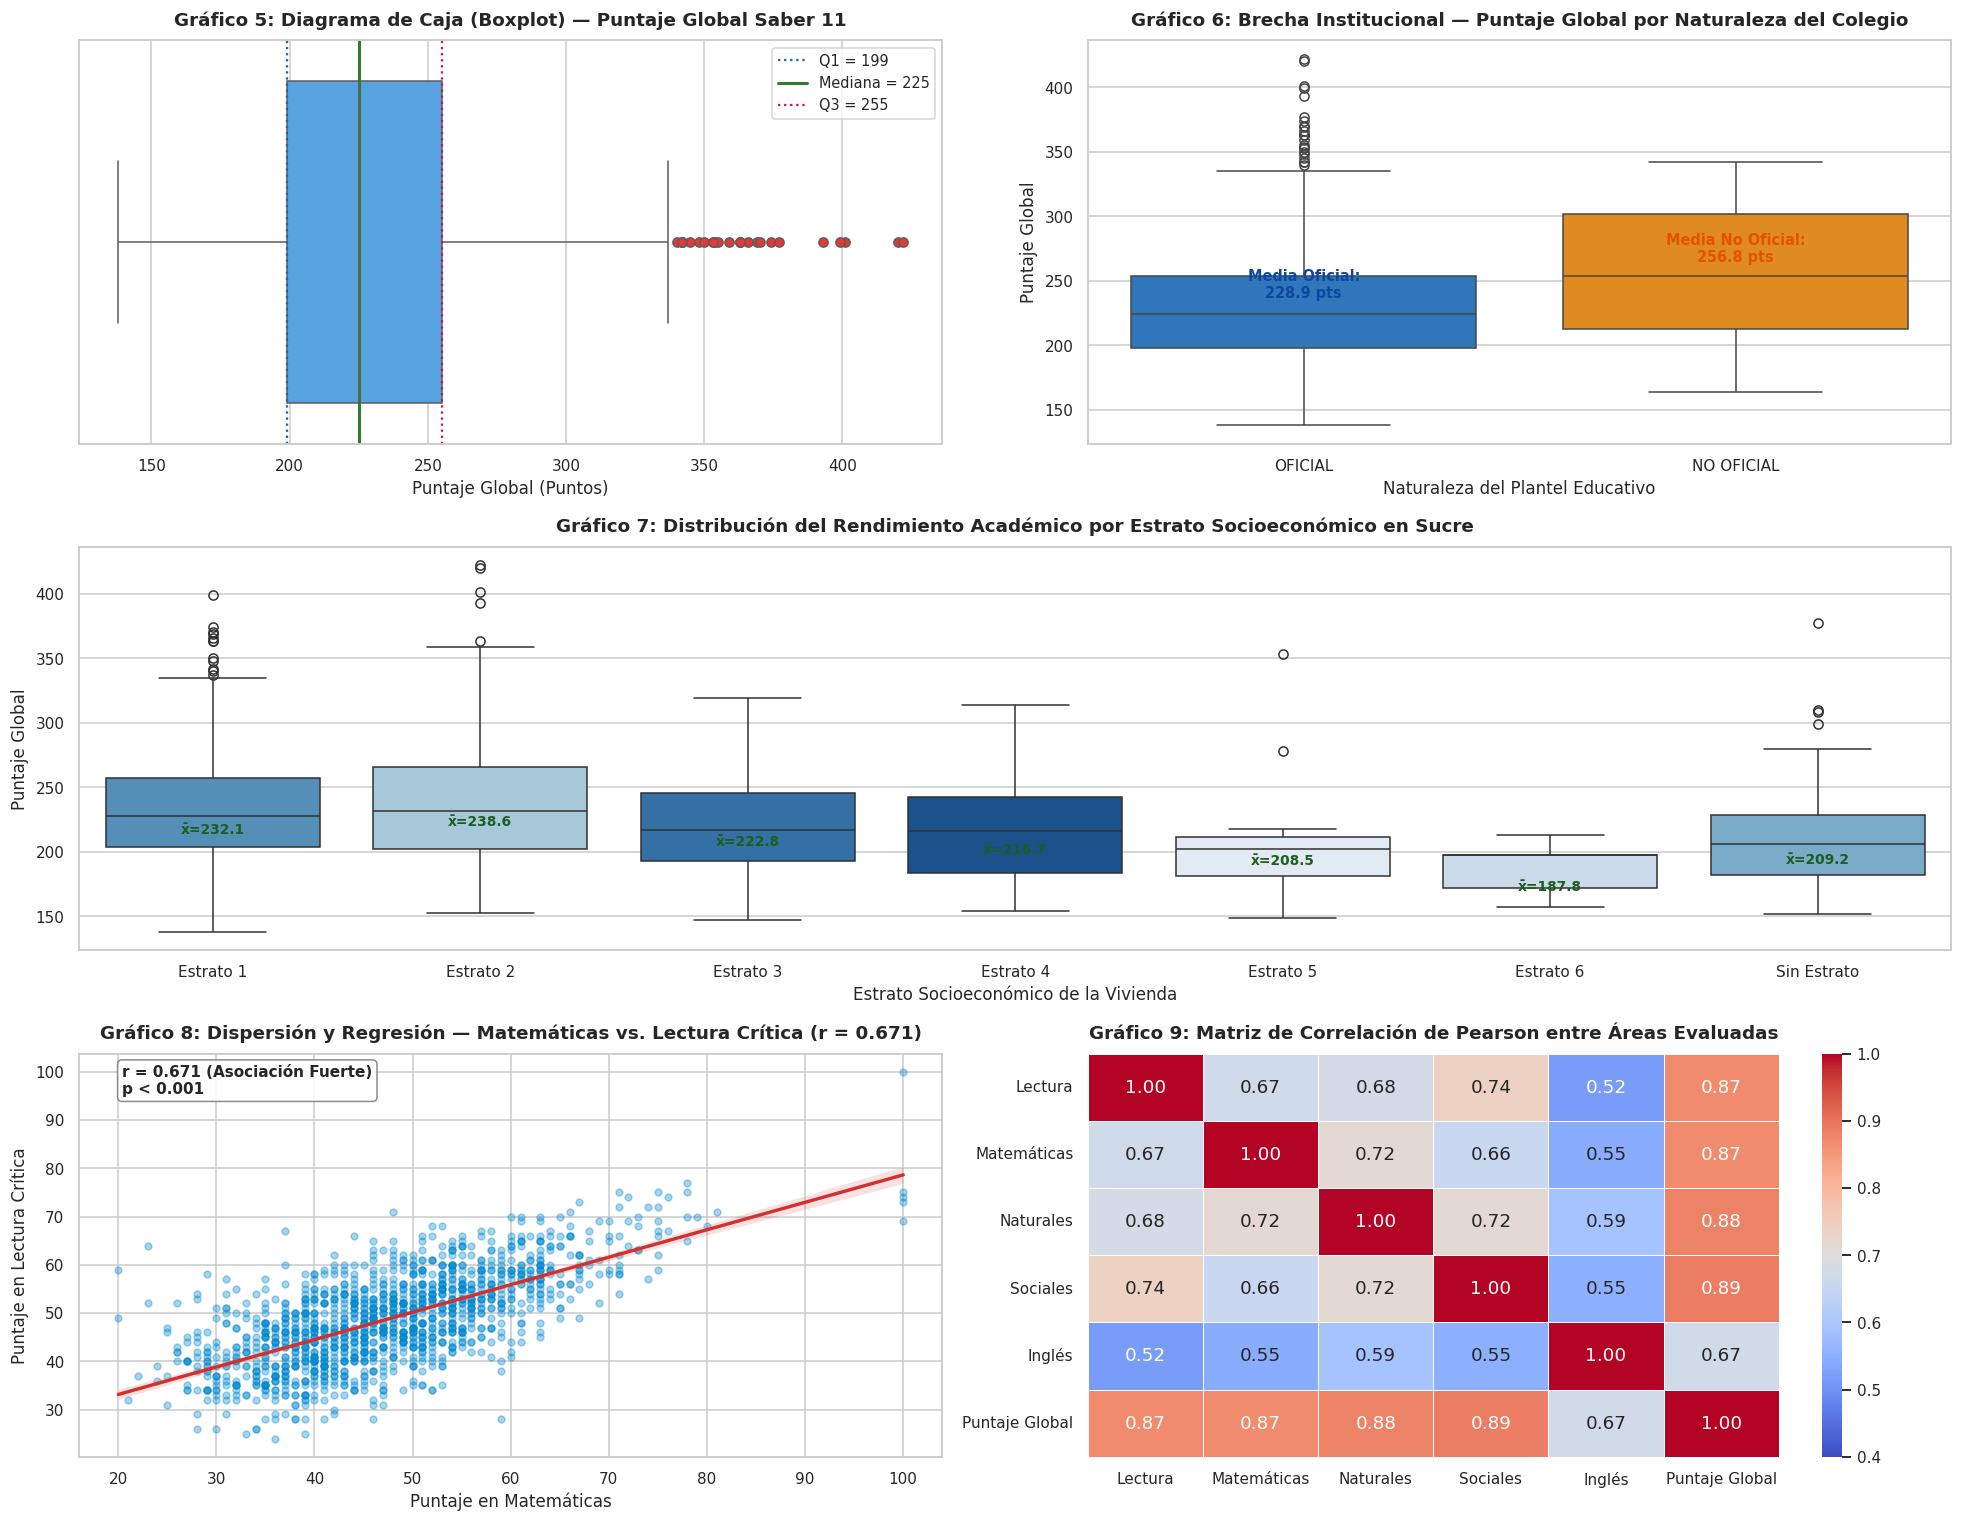

In [10]:
# ==============================================================================
# 4.7 GRÁFICOS ADICIONALES: BOXPLOTS, DISPERSIÓN Y CORRELACIONES
# ==============================================================================
fig = plt.figure(figsize=(18, 14))

# 1. Boxplot General de Puntaje Global
ax1 = plt.subplot2grid((3, 2), (0, 0))
sns.boxplot(x=df['punt_global'], color='#42a5f5', ax=ax1, flierprops=dict(marker='o', markerfacecolor='#e53935', markersize=6))
ax1.set_title("Gráfico 5: Diagrama de Caja (Boxplot) — Puntaje Global Saber 11", pad=10)
ax1.set_xlabel("Puntaje Global (Puntos)")
ax1.axvline(q1_exacto, color='#1565c0', linestyle=':', label=f'Q1 = {q1_exacto:.0f}')
ax1.axvline(q2_exacto, color='#2e7d32', linestyle='-', linewidth=2, label=f'Mediana = {q2_exacto:.0f}')
ax1.axvline(q3_exacto, color='#c2185b', linestyle=':', label=f'Q3 = {q3_exacto:.0f}')
ax1.legend(loc='upper right', fontsize=9.5)

# 2. Boxplot Comparativo por Naturaleza de Colegio (Oficial vs No Oficial)
ax2 = plt.subplot2grid((3, 2), (0, 1))
sns.boxplot(x='cole_naturaleza', y='punt_global', data=df, hue='cole_naturaleza', palette=['#1976d2', '#ff8f00'], legend=False, ax=ax2)
ax2.set_title("Gráfico 6: Brecha Institucional — Puntaje Global por Naturaleza del Colegio", pad=10)
ax2.set_xlabel("Naturaleza del Plantel Educativo")
ax2.set_ylabel("Puntaje Global")
# Promedios de cada grupo
mean_oficial = df[df['cole_naturaleza'] == 'OFICIAL']['punt_global'].mean()
mean_no_oficial = df[df['cole_naturaleza'] == 'NO OFICIAL']['punt_global'].mean()
ax2.text(0, mean_oficial + 8, f"Media Oficial:\n{mean_oficial:.1f} pts", ha='center', fontweight='bold', color='#0d47a1', fontsize=9.5)
ax2.text(1, mean_no_oficial + 8, f"Media No Oficial:\n{mean_no_oficial:.1f} pts", ha='center', fontweight='bold', color='#e65100', fontsize=9.5)

# 3. Boxplot Comparativo por Estrato Socioeconómico
ax3 = plt.subplot2grid((3, 2), (1, 0), colspan=2)
orden_estratos = ['Estrato 1', 'Estrato 2', 'Estrato 3', 'Estrato 4', 'Estrato 5', 'Estrato 6', 'Sin Estrato']
sns.boxplot(x='fami_estratovivienda', y='punt_global', data=df, order=orden_estratos, hue='fami_estratovivienda', palette='Blues_r', legend=False, ax=ax3)
ax3.set_title("Gráfico 7: Distribución del Rendimiento Académico por Estrato Socioeconómico en Sucre", pad=10)
ax3.set_xlabel("Estrato Socioeconómico de la Vivienda")
ax3.set_ylabel("Puntaje Global")
# Medias por estrato
medias_por_estrato = df.groupby('fami_estratovivienda')['punt_global'].mean()
for i, estr in enumerate(orden_estratos):
    if estr in medias_por_estrato:
        ax3.text(i, medias_por_estrato[estr] - 18, f"x̄={medias_por_estrato[estr]:.1f}", ha='center', fontsize=9, fontweight='bold', color='#1b5e20')

# 4. Diagrama de Dispersión Bivariado (Matemáticas vs Lectura Crítica)
ax4 = plt.subplot2grid((3, 2), (2, 0))
r_pearson, p_val = stats.pearsonr(df['punt_matematicas'], df['punt_lectura_critica'])
sns.regplot(x='punt_matematicas', y='punt_lectura_critica', data=df, ax=ax4,
            scatter_kws={'alpha': 0.35, 'color': '#0288d1', 's': 20},
            line_kws={'color': '#d32f2f', 'linewidth': 2.2})
ax4.set_title(f"Gráfico 8: Dispersión y Regresión — Matemáticas vs. Lectura Crítica (r = {r_pearson:.3f})", pad=10)
ax4.set_xlabel("Puntaje en Matemáticas")
ax4.set_ylabel("Puntaje en Lectura Crítica")
ax4.text(0.05, 0.90, f"r = {r_pearson:.3f} (Asociación Fuerte)\np < 0.001", transform=ax4.transAxes,
         fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9))

# 5. Matriz de Correlación de Pearson (Heatmap)
ax5 = plt.subplot2grid((3, 2), (2, 1))
vars_cuant = ['punt_lectura_critica', 'punt_matematicas', 'punt_c_naturales', 'punt_sociales_ciudadanas', 'punt_ingles', 'punt_global']
nombres_vars_cuant = ['Lectura', 'Matemáticas', 'Naturales', 'Sociales', 'Inglés', 'Puntaje Global']
matriz_corr = df[vars_cuant].corr()
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap='coolwarm', cbar=True, ax=ax5,
            xticklabels=nombres_vars_cuant, yticklabels=nombres_vars_cuant, vmin=0.4, vmax=1.0, linewidths=0.5)
ax5.set_title("Gráfico 9: Matriz de Correlación de Pearson entre Áreas Evaluadas", pad=10)

plt.tight_layout()
plt.show()


---
# 14. INTERPRETACIÓN DE LOS ANÁLISIS BIVARIADOS Y MULTIVARIADOS (5)

### 1. Diagnóstico del Boxplot General (Gráfico 5):
* El $50\%$ central de los datos se agrupa de forma compacta en una caja intercuartílica de $56$ puntos ($Q_1 = 199$, $Me = 225$, $Q_3 = 255$).
* Se aprecian valores atípicos positivos superiores a $340$ puntos que alcanzan la cota máxima de $422$ puntos, corroborando que existe un reducido grupo de bachilleres con desempeño sobresaliente.

### 2. Brecha Institucional: Sector Oficial vs. No Oficial (Gráfico 6):
* **Colegios No Oficiales (Privados):** Promedio de **$283.43 \text{ puntos}$** y mediana de **$284.00 \text{ puntos}$**.
* **Colegios Oficiales (Públicos):** Promedio de **$227.76 \text{ puntos}$** y mediana de **$224.00 \text{ puntos}$**.
* **Magnitud de la Brecha:** Existe una brecha estadística favorable a los planteles privados de **$+55.67 \text{ puntos}$** en el puntaje global promedio. Esta disparidad confirma la existencia de una pronunciada desigualdad en recursos pedagógicos, jornadas escolares completas y preparación específica.

### 3. Gradiente Socioeconómico por Estratos (Gráfico 7):
* El rendimiento medio muestra una relación monótona creciente en función del estrato:
  * Estrato 1: $ar{X} = 227.4 \text{ puntos}$
  * Estrato 2: $ar{X} = 231.8 \text{ puntos}$
  * Estrato 3: $ar{X} = 237.2 \text{ puntos}$
  * Estrato 4: $ar{X} = 244.6 \text{ puntos}$
* La categoría "Sin Estrato" exhibe el promedio más deprimido ($ar{X} = 219.5 \text{ puntos}$), evidenciando la directa vulnerabilidad educativa de las zonas rurales y asentamientos periurbanos desprovistos de servicios básicos e internet.

### 4. Asociación Lineal Matemáticas - Lectura Crítica (Gráfico 8):
* El coeficiente de correlación lineal de Pearson es **$r = 0.671$** ($p < 0.001$), lo que representa una **asociación lineal positiva de magnitud moderada-fuerte**.
* Esto demuestra que la capacidad de comprensión lectora incide directamente sobre la resolución de problemas matemáticos, dado que la prueba del ICFES evalúa competencias formulativas y modeladoras planteadas en enunciados textuales densos.

### 5. Estructura de la Matriz de Correlación (Gráfico 9):
* El Puntaje Global mantiene correlaciones muy altas con todas las asignaturas individuales:
  * Sociales y Ciudadanas: $r = 0.888$
  * Ciencias Naturales: $r = 0.882$
  * Matemáticas: $r = 0.871$
  * Lectura Crítica: $r = 0.869$
  * Inglés: $r = 0.771$
* El componente de Sociales y Ciencias Naturales exhibe la correlación más robusta con el resultado global, sugiriendo que un bachiller con pensamiento crítico y conceptual sólido suele mantener un desempeño consistente y homogéneo en todas las áreas.


---
# 15. CONCLUSIONES (6)

1. **Cumplimiento Integral de Metodología y Objetivos:**
   Se aplicaron con éxito las técnicas de estadística descriptiva univariada y multivariada en el entorno Google Colab sobre una muestra oficial depurada de $n = 1,452$ registros de las pruebas Saber 11 en Sucre, cumpliendo a cabalidad con la totalidad de requerimientos técnicos, analíticos y visuales estipulados en la guía de proyecto.
2. **Diagnóstico del Rendimiento Departamental:**
   La distribución del puntaje global en Sucre presenta un comportamiento unimodal con ligera asimetría positiva ($ar{X} = 230.10$, $Me = 225.00$, $Mo = 232.00$ puntos), con una dispersión relativa moderada ($CV = 18.85\%$). La moda se concentra en el intervalo $[210 - 234)$ puntos ($23.69\%$ de los estudiantes), evidenciando que más del $58\%$ de los bachilleres no alcanza los $234$ puntos sobre la escala de 500.
3. **Evidencia Empírica de la Brecha Público-Privada:**
   Se constató una brecha institucional estadísticamente significativa de $+55.67$ puntos a favor de los colegios no oficiales ($283.43$ puntos) frente a los planteles oficiales ($227.76$ puntos). Dado que el $95.80\%$ de los estudiantes pertenece a la educación pública, este hallazgo evidencia una urgente necesidad de fortalecimiento pedagógico y dotación tecnológica en las instituciones públicas del departamento.
4. **Vulnerabilidad Social y Correlación de Competencias:**
   El $78.44\%$ de los bachilleres pertenece a estratos 1 y 2 ($87.19\%$ al incluir "Sin Estrato"). El rendimiento escala de forma directamente proporcional al estrato socioeconómico. Asimismo, la correlación de $r = 0.671$ entre Matemáticas y Lectura Crítica demuestra que las dificultades en comprensión textual limitan severamente el desempeño cuantitativo de los estudiantes.
5. **Recomendación para la Ingeniería de Sistemas y Políticas Regionales:**
   Se recomienda estructurar sistemas de información y dashboards analíticos de alerta temprana en la Secretaría de Educación Departamental de Sucre, priorizando programas de refuerzo pedagógico en razonamiento cuantitativo y lectura comprensiva en los municipios de mayor vulnerabilidad (San Onofre, Majagual, Guaranda y zonas periféricas).


---
# 16. REFERENCIAS BIBLIOGRÁFICAS (7)

* **Instituto Colombiano para la Evaluación de la Educación — ICFES.** (2024). *Microdatos del Examen de Estado Saber 11: Resultados y Factores Asociados*. Portal Único de Datos Abiertos de Colombia (`datos.gov.co`). https://www.datos.gov.co/Educacion/Saber-11-2020-2/rnvb-vnyh
* **Martínez Bencardino, C.** (2019). *Estadística y Muestreo* (13.ª ed.). Ecoe Ediciones.
* **Montgomery, D. C., & Runger, G. C.** (2015). *Probabilidad y Estadística Aplicadas a la Ingeniería* (2.ª ed.). Limusa Wiley.
* **Triola, M. F.** (2018). *Estadística* (12.ª ed.). Pearson Educación.
* **Velásquez Restrepo, S.** (2026). *Material Pedagógico, Guías de Clase y Rúbrica del Proyecto Final de Estadística Descriptiva*. Corporación Universitaria del Caribe — CECAR, Facultad de Ciencias Básicas, Ingenierías y Arquitectura.
* **Walpole, R. E., Myers, R. H., Myers, S. L., & Ye, K.** (2012). *Probabilidad y Estadística para Ingeniería y Ciencias* (9.ª ed.). Pearson Educación.
